# End-to-End Machine Learning Consultancy Project
## Predicting term-deposit subscription: UCI Bank Marketing

This notebook is the experimental record behind the technical report. It follows the brief:

| Part | Topic |
|---|---|
| A | Machine learning problem analysis |
| B | Supervised vs unsupervised learning (with an empirical probe) |
| C | Exploratory data analysis and data-quality investigation |
| D | Data preparation, feature engineering and controlled preprocessing experiments |
| E | Three tuned base models |
| F | Ensemble learning (soft voting and stacking) from the best two models |
| H | Evaluation and recommendation |

All reusable logic lives in `src/`; the notebook calls it so results are reproducible with `python -m src.train`.
The random seed is fixed at 42 throughout.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
%matplotlib inline

from src.config import FIG_DIR, RESULTS_DIR, RANDOM_STATE
from src.data_loading import load_raw
from src import eda, experiments as ex, evaluation as ev
from src.train import (prepare_data, tune_base_models, oof_probas, rank_models,
                       build_ensembles, fit_and_test)
from src.models import MODEL_LABELS
RESULTS_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)

## Part A: Machine learning problem analysis

**Business background.** A Portuguese retail bank ran telephone campaigns between May 2008 and November 2010 to sell term deposits (Moro, Cortez and Rita, 2014). Each call costs agent time, and most clients say no.

**Business objective.** Contact fewer clients while still reaching most of those who will subscribe, so that the cost per acquired deposit falls.

**ML objective.** Estimate, *before a call is made*, the probability that a client subscribes (`y = yes`), and rank clients by that probability. This is **binary classification**.

In [2]:
raw = load_raw()
print("Shape:", raw.shape)
raw.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
feature_desc = pd.DataFrame([
 ("age","client","numeric","Age in years"),
 ("job","client","nominal","Type of job (12 levels incl. 'unknown')"),
 ("marital","client","nominal","Marital status"),
 ("education","client","nominal","Highest education level"),
 ("default","client","nominal","Has credit in default?"),
 ("housing","client","nominal","Has a housing loan?"),
 ("loan","client","nominal","Has a personal loan?"),
 ("contact","last contact","nominal","Cellular or telephone"),
 ("month","last contact","nominal","Month of last contact"),
 ("day_of_week","last contact","nominal","Weekday of last contact"),
 ("duration","last contact","numeric","Call length in seconds (known only AFTER the call: leakage)"),
 ("campaign","campaign","numeric","Contacts in this campaign, incl. the last"),
 ("pdays","campaign","numeric","Days since previous campaign contact (999 = never)"),
 ("previous","campaign","numeric","Contacts before this campaign"),
 ("poutcome","campaign","nominal","Outcome of previous campaign"),
 ("emp_var_rate","macro","numeric","Employment variation rate (quarterly)"),
 ("cons_price_idx","macro","numeric","Consumer price index (monthly)"),
 ("cons_conf_idx","macro","numeric","Consumer confidence index (monthly)"),
 ("euribor3m","macro","numeric","3-month Euribor rate (daily)"),
 ("nr_employed","macro","numeric","Number employed (quarterly, thousands)"),
 ("y","target","binary","Subscribed a term deposit?"),
], columns=["feature","group","type","description"]).set_index("feature")
feature_desc

,group,type,description
feature,,,
age,client,numeric,Age in years
job,client,nominal,Type of job (12 levels incl. 'unknown')
marital,client,nominal,Marital status
education,client,nominal,Highest education level
default,client,nominal,Has credit in default?
housing,client,nominal,Has a housing loan?
loan,client,nominal,Has a personal loan?
contact,last contact,nominal,Cellular or telephone
month,last contact,nominal,Month of last contact


In [4]:
print(raw.dtypes.value_counts())
eda.class_balance(raw)

str        11
int64       5
float64     5
Name: count, dtype: int64


,count,pct
y,,
no,36548,88.73
yes,4640,11.27


**Task type.** The target `y` is a labelled binary outcome, so the problem is supervised **classification**. Regression does not fit (no continuous target) and clustering would ignore the label we actually care about. Part B tests this empirically.

## Part B: Supervised vs unsupervised learning, an empirical probe

If unsupervised learning were sufficient, natural clusters in the client data would separate subscribers from non-subscribers. Below, k-means is fitted on the preprocessed features (label hidden) for k = 2 to 8, and the clusters are compared with the label using the Adjusted Rand Index (ARI, 0 = no agreement beyond chance).

In [5]:
raw_, clean, X_tr, X_te, y_tr, y_te = prepare_data()
probe = ex.unsupervised_probe(X_tr, y_tr)
probe

,silhouette,ARI_vs_label,max_cluster_sub_rate,min_cluster_sub_rate
k,,,,
2,0.1806,0.0618,0.1995,0.0567
3,0.1856,0.1042,0.6450,0.0559
4,0.1130,0.0432,0.6450,0.0400
5,0.1295,0.0544,0.6450,0.0397
6,0.1254,0.0352,0.6450,0.0389
7,0.1303,0.0363,0.6481,0.0392
8,0.1361,0.0239,0.6481,0.0425


ARI stays close to zero for every k: the clusters mainly reflect the macroeconomic period and contact channel, not purchase intent. Some clusters do have higher subscription rates (useful for segmentation), but a supervised model trained on the label is required for the ranking task.

## Part C: Exploratory data analysis and data-quality investigation
### C1. Descriptive statistics and skewness

In [6]:
eda.descriptive_stats(raw)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000,0.785,0.791
duration,41188.0,258.285,259.279,0.000,102.000,180.000,319.000,4918.000,3.263,20.248
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000,4.763,36.980
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000,-4.922,22.229
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000,3.832,20.109
emp_var_rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400,-0.724,-1.063
cons_price_idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767,-0.231,-0.830
cons_conf_idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900,0.303,-0.359
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045,-0.709,-1.407
nr_employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100,-1.044,-0.004


### C2. Missing values (NaN and disguised 'unknown')

In [7]:
q = eda.quality_report(raw); q

,dtype,n_unique,nan,unknown,unknown_pct
column,,,,,
age,int64,78,0,0,0.00
job,str,12,0,330,0.80
marital,str,4,0,80,0.19
education,str,8,0,1731,4.20
default,str,3,0,8597,20.87
housing,str,3,0,990,2.40
loan,str,3,0,990,2.40
contact,str,2,0,0,0.00
month,str,10,0,0,0.00


### C3. Duplicates

In [8]:
eda.duplicate_report(raw)

{'exact_duplicate_rows': 12,
 'rows_involved_in_duplicates': 24,
 'feature_duplicates_with_conflicting_label': 0}

### C4. Outliers (Tukey 1.5 x IQR fences)

In [9]:
eda.iqr_outliers(raw, ["age","duration","campaign","previous","cons_conf_idx"])

,lower_fence,upper_fence,n_outliers,pct
column,,,,
age,9.50,69.50,469,1.14
duration,-223.50,644.50,2963,7.19
campaign,-2.00,6.00,2406,5.84
previous,0.00,0.00,5625,13.66
cons_conf_idx,-52.15,-26.95,447,1.09


### C5. Inconsistencies, rare levels and noise

In [10]:
eda.inconsistency_checks(raw)

{'pdays999_but_previous>0': 4110,
 'poutcome_nonexistent_but_previous>0': 0,
 'previous>0_but_poutcome_nonexistent': 0,
 'housing_unknown_rows': 990,
 'housing_and_loan_unknown_same_rows': True,
 'default_yes_count': 3,
 'education_illiterate_count': 18,
 'duration_zero_calls': 4,
 'pdays_999_pct': np.float64(96.32)}

### C6. Class imbalance and figures

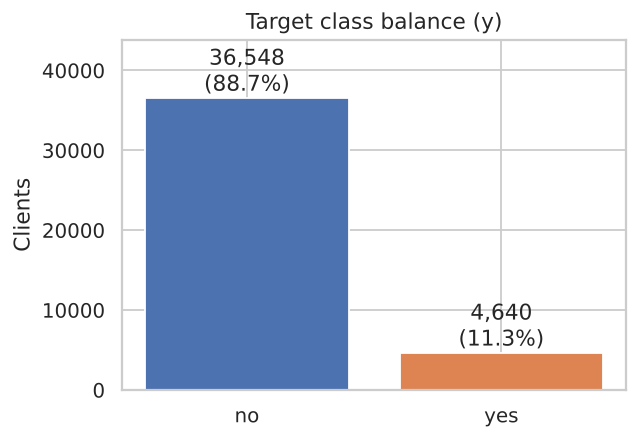

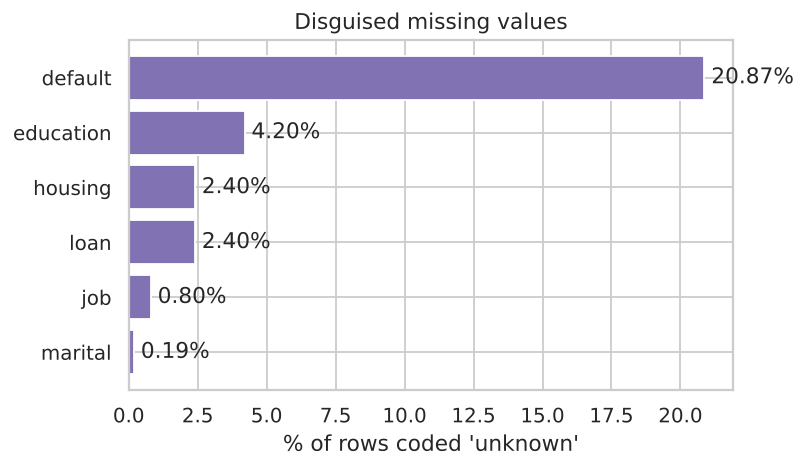

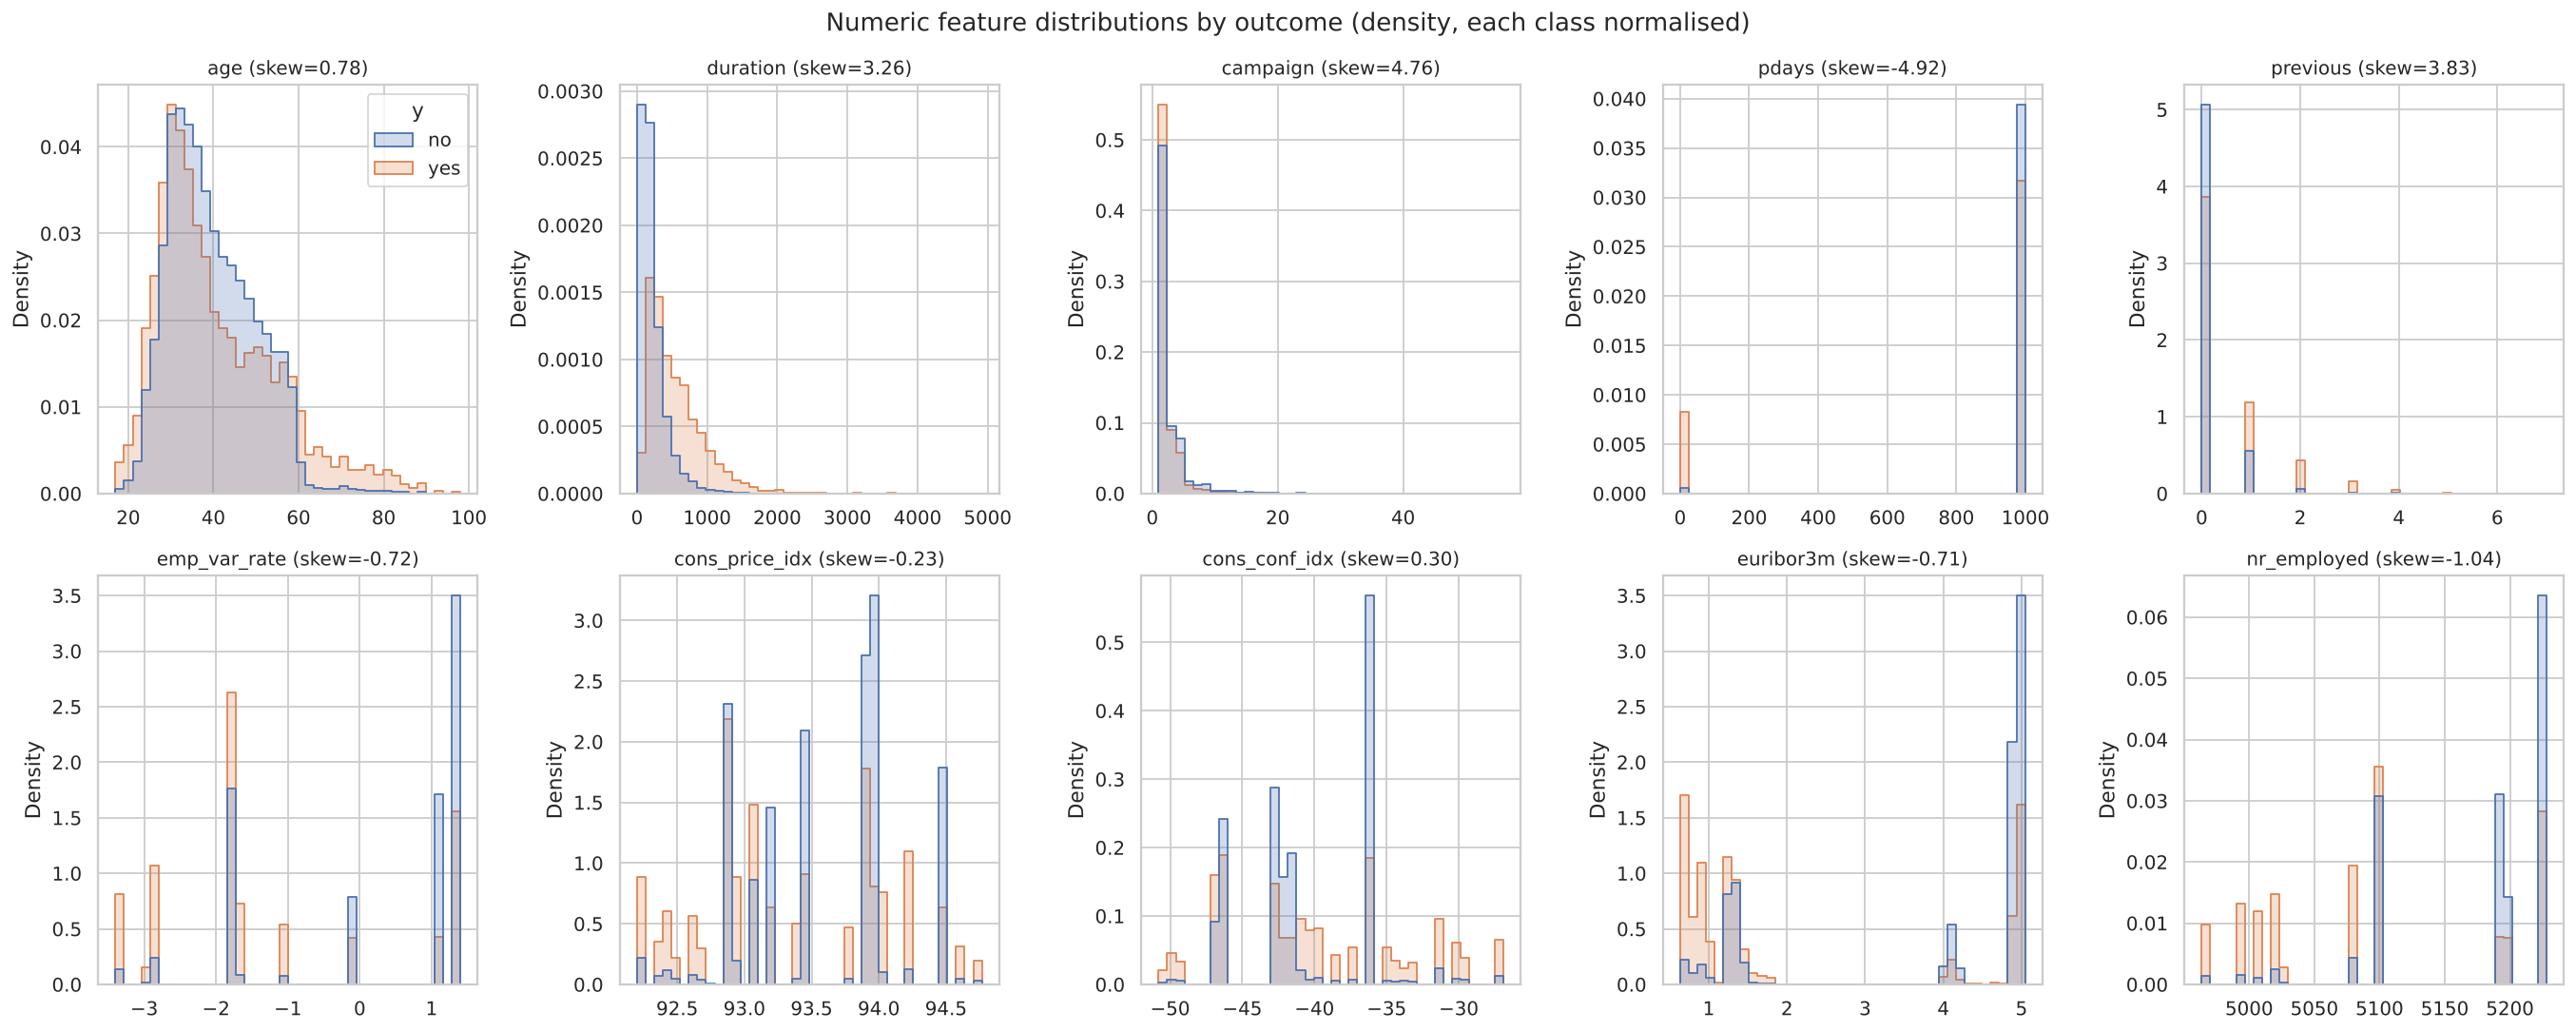

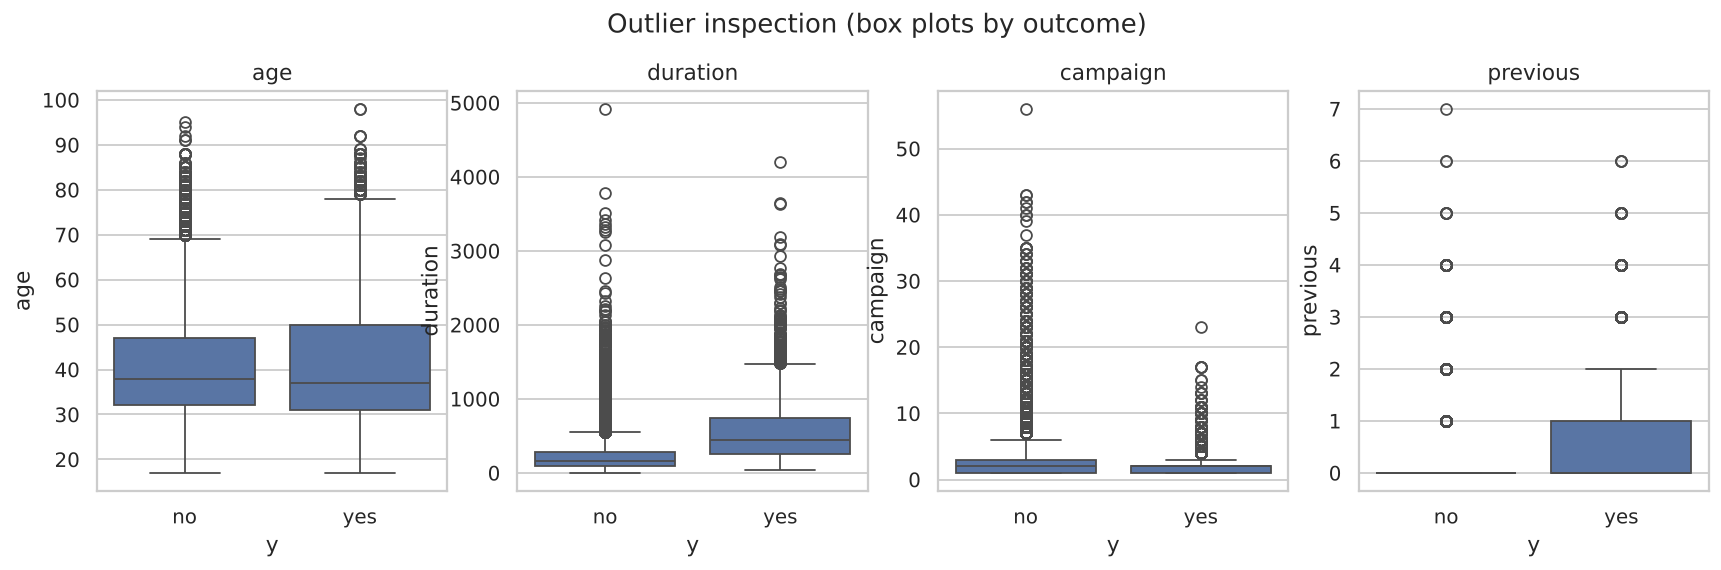

In [11]:
corr = eda.run_all_figures(raw)
for f in ["01_class_balance.png","06_unknown_values.png","02_numeric_distributions.png","03_boxplots.png"]:
    display(Image(FIG_DIR / f))

### C7. Correlation and association with the target

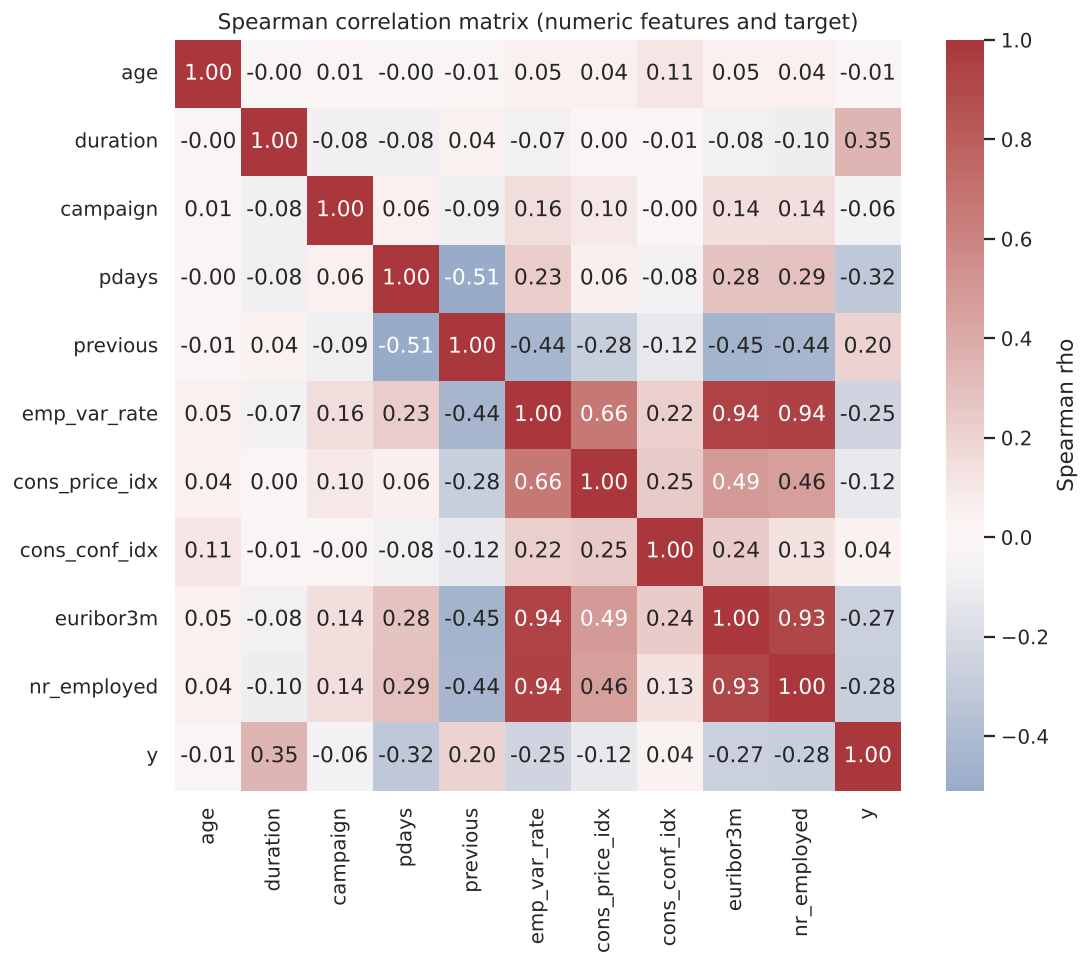

Spearman correlation with y (numeric):
duration          0.349
pdays            -0.325
nr_employed      -0.284
euribor3m        -0.267
emp_var_rate     -0.247
previous          0.201
cons_price_idx   -0.122
campaign         -0.064
cons_conf_idx     0.041
age              -0.012
Name: y, dtype: float64

Cramer's V with y (categorical):
poutcome       0.320
month          0.274
job            0.153
contact        0.145
default        0.099
education      0.068
marital        0.055
day_of_week    0.025
housing        0.012
loan           0.005
Name: cramers_v, dtype: float64


In [12]:
display(Image(FIG_DIR / "04_correlation_heatmap.png"))
print("Spearman correlation with y (numeric):")
print(corr["y"].drop("y").sort_values(key=abs, ascending=False).round(3))
print("\nCramer's V with y (categorical):")
print(eda.categorical_association(raw))

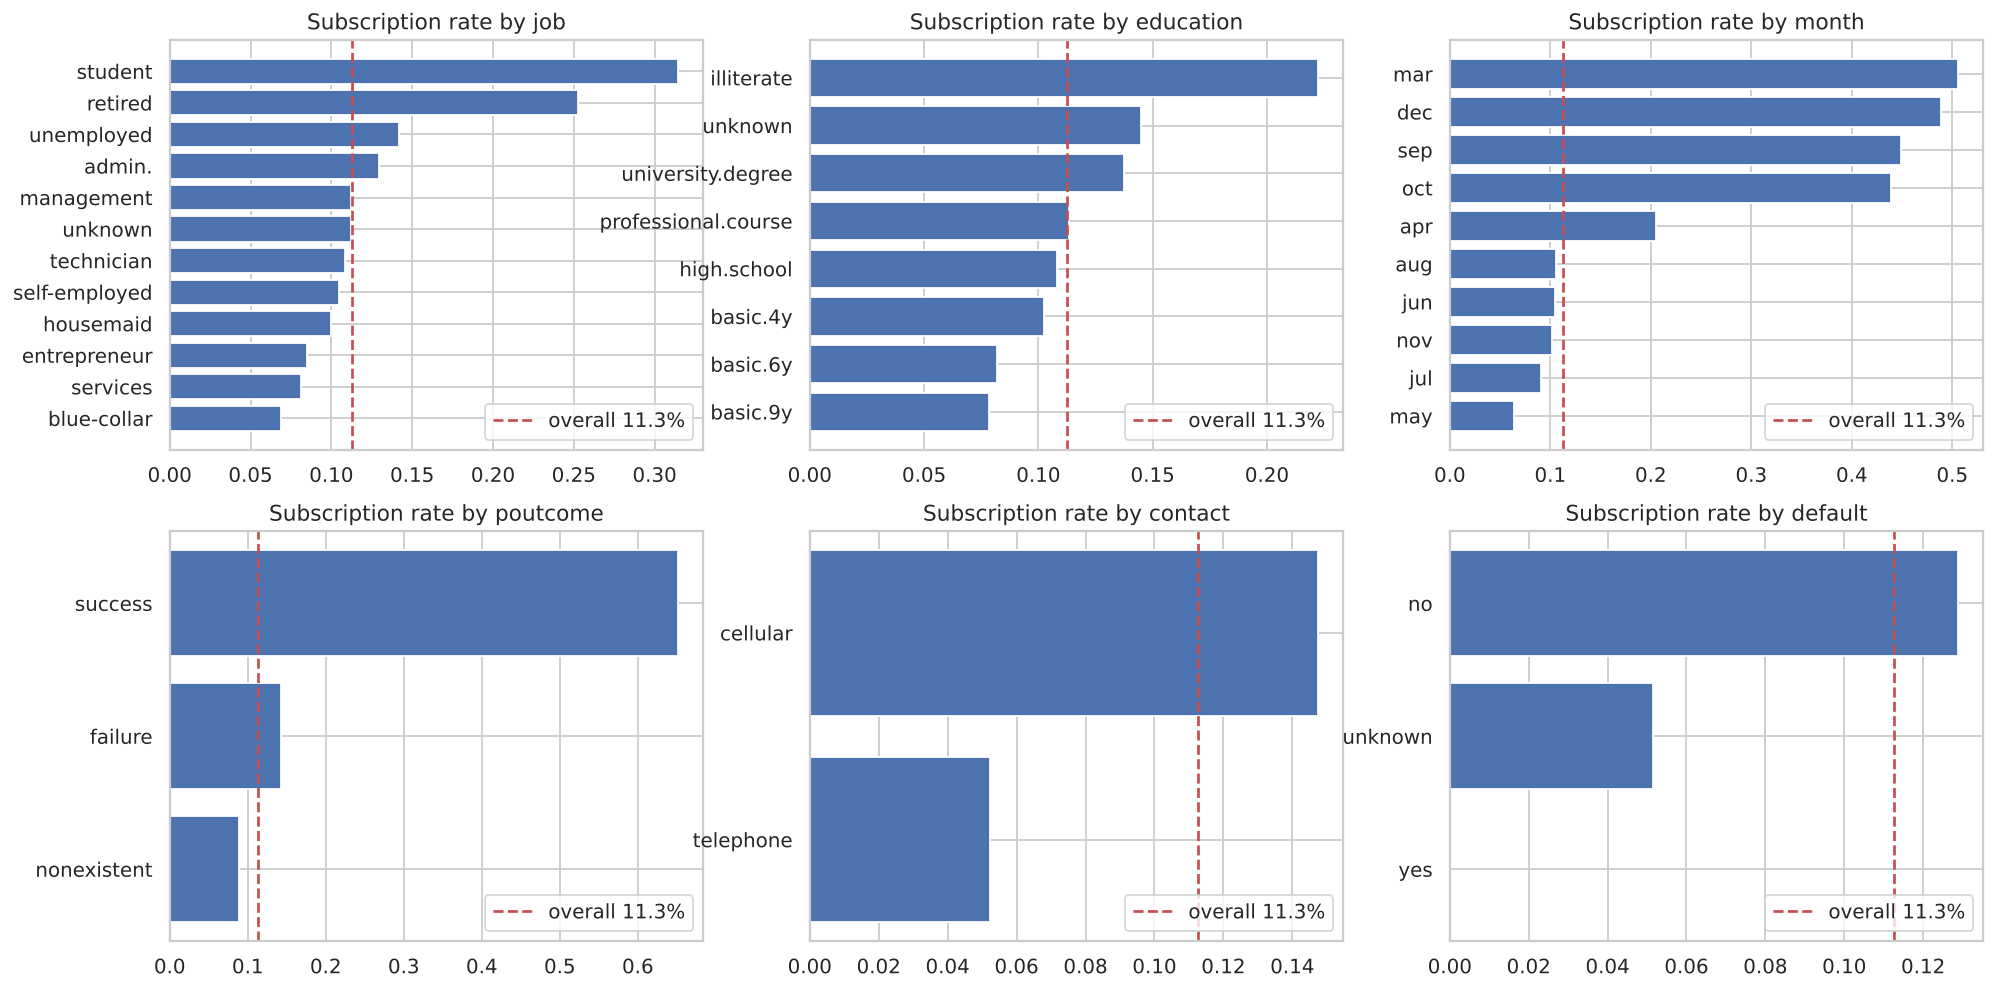

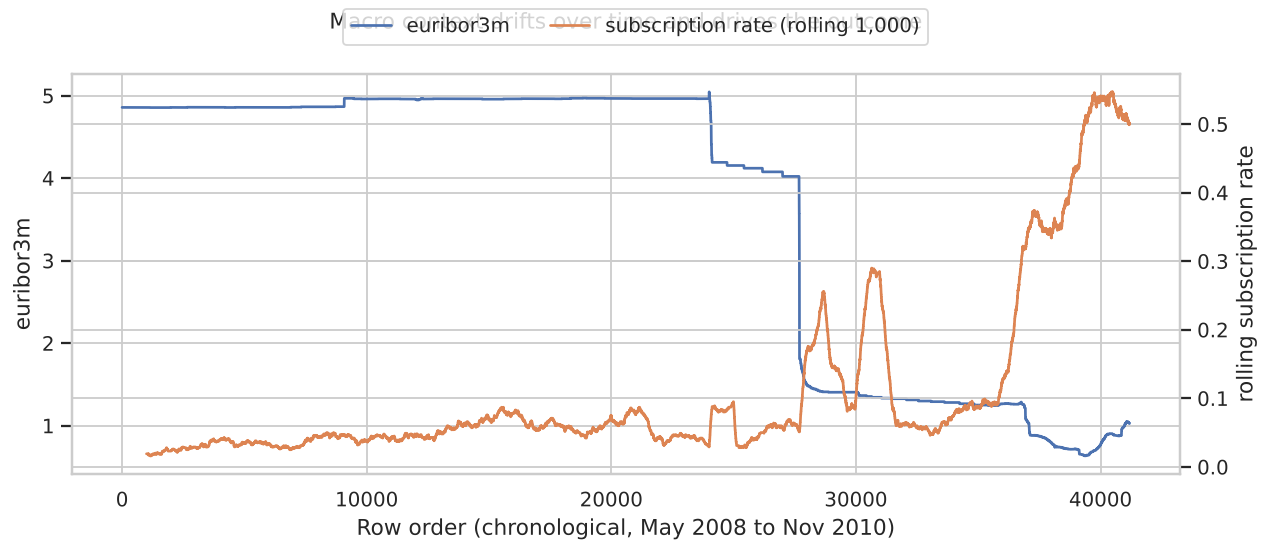

In [13]:
display(Image(FIG_DIR / "05_categorical_rates.png"))
display(Image(FIG_DIR / "07_temporal_drift.png"))

In [14]:
# Duplicated rows by label, and duplicates in feature space only (a noise indicator)
print("Exact duplicates:", raw.duplicated().sum())
print("Feature-only duplicates (ignoring y):", raw.drop(columns="y").duplicated().sum())

Exact duplicates: 12


Feature-only duplicates (ignoring y): 12


## Part D: Data preparation and feature engineering
### D1. Stateless cleaning and feature engineering (safe before the split)
* drop 12 exact duplicates
* drop `duration` (target leakage)
* `default`: merge the 3 `yes` values into `unknown`
* `pdays` → `prev_contacted` flag (999 is a sentinel for 96% of rows)
* `campaign` → `log1p(campaign)` to reduce skew

### D2. Fitted steps (inside the pipeline, trained on training folds only)
* 'unknown' handling (kept as a category, or mode imputation)
* correlation filter on numeric features (|Spearman ρ| > 0.90)
* standard scaling
* one-hot encoding with rare levels (< 30 rows) grouped as "infrequent"
* optional PCA, optional SMOTE / undersampling

In [15]:
print("Cleaned dataset:", clean.shape, "->", "data/processed/bank_marketing_cleaned.csv")
print("Train:", X_tr.shape, "positive rate %.4f" % y_tr.mean())
print("Test :", X_te.shape, "positive rate %.4f" % y_te.mean())
clean.head()

Cleaned dataset: (41176, 20) -> data/processed/bank_marketing_cleaned.csv
Train: (32940, 19) positive rate 0.1127
Test : (8236, 19) positive rate 0.1127


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,age,campaign_log,previous,prev_contacted,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent,56,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent,57,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent,37,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent,40,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent,56,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no


In [16]:
from src.preprocessing import make_pipeline, build_preprocessor
from sklearn.linear_model import LogisticRegression
demo = make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced"))
demo.fit(X_tr, y_tr)
cf = demo.named_steps["prep"].named_transformers_["num"].named_steps["corr_filter"]
print("Correlation filter dropped:", cf.dropped_)
print("Encoded feature count:", len(demo.named_steps["prep"].get_feature_names_out()))
demo

Correlation filter dropped: ['euribor3m', 'nr_employed']
Encoded feature count: 59


,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['job','marital','education',...,'cons_conf_idx','euribor3m','nr_employed']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


### D3. Controlled preprocessing experiments
Each row changes one decision only. Scores are 5-fold stratified CV means on the training set. PR-AUC (average precision) is the primary metric because the positive class is only 11%.

In [17]:
t = time.time()
pre_exp = ex.preprocessing_experiments(X_tr, y_tr)
pre_exp.to_csv(RESULTS_DIR / "preprocessing_experiments.csv")
print(f"{time.time()-t:.0f}s")
pre_exp[["roc_auc","pr_auc","pr_auc_std","f1","recall","precision","fit_seconds"]]

59s


roc_auc  pr_auc  pr_auc_std      f1  recall  precision  fit_seconds
experiment        model variant                                                                                           
Unknown handling  LR    keep 'unknown' as category      0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          2.6
                        mode imputation                 0.7902  0.4441      0.0113  0.4481  0.6260     0.3490          1.0
                  HGB   keep 'unknown' as category      0.7906  0.4599      0.0183  0.4653  0.6138     0.3748          2.0
                        mode imputation                 0.7913  0.4607      0.0176  0.4642  0.6147     0.3731          2.0
Imbalance         LR    none                            0.7892  0.4494      0.0135  0.3442  0.2323     0.6658          0.9
                        class weights                   0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          1.0
                        SMOTE                           0.7869  0.4401      0.0132  0.4385  0.6271     0.3371          1.4
                        random undersampling            0.7878  0.4415      0.0121  0.4417  0.6276     0.3408          0.8
                  HGB   none                            0.7941  0.4619      0.0173  0.3586  0.2479     0.6492          1.9
                        class weights                   0.7906  0.4599      0.0183  0.4653  0.6138     0.3748          2.0
                        SMOTE                           0.7896  0.4487      0.0134  0.4039  0.3126     0.5714          5.9
                        random undersampling            0.7828  0.4307      0.0173  0.4321  0.6327     0.3281          1.6
Scaling           LR    standard scaling                0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          0.9
                        no scaling                      0.7873  0.4274      0.0113  0.4392  0.6319     0.3366         18.1
Feature selection LR    correlation filter |rho|>0.90   0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          0.9
                        all features                    0.7899  0.4460      0.0130  0.4504  0.6225     0.3529          1.1
                  HGB   correlation filter |rho|>0.90   0.7906  0.4599      0.0183  0.4653  0.6138     0.3748          2.0
                        all features                    0.7999  0.4655      0.0154  0.4731  0.6227     0.3814          2.1
PCA               LR    no PCA                          0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          0.9
                        PCA (95% variance)              0.7866  0.4283      0.0091  0.4286  0.6295     0.3249          0.8
                  HGB   no PCA                          0.7906  0.4599      0.0183  0.4653  0.6138     0.3748          2.1
                        PCA (95% variance)              0.7869  0.4388      0.0101  0.4576  0.6130     0.3652          6.8

In [18]:
fig, ax = plt.subplots(figsize=(10, 7))
d = pre_exp.reset_index()
d["label"] = d["experiment"] + " | " + d["model"] + " | " + d["variant"]
ax.barh(d["label"], d["pr_auc"], xerr=d["pr_auc_std"], color=sns.color_palette("deep")[0])
ax.set_xlim(0.30, 0.48); ax.invert_yaxis(); ax.set_xlabel("5-fold CV PR-AUC (mean ± sd)")
ax.set_title("Impact of each preprocessing decision")
fig.savefig(FIG_DIR / "08_preprocessing_experiments.png", dpi=130, bbox_inches="tight"); plt.show()

### D4. Leakage benchmark: what `duration` would do

In [19]:
clean_dur = __import__("src.preprocessing", fromlist=["x"]).clean_and_engineer(raw, drop_leakage=False)
from src.data_loading import split_xy
Xd, yd = split_xy(clean_dur)
Xd_tr = Xd.loc[X_tr.index]; yd_tr = yd.loc[X_tr.index]
leak = ex.leakage_benchmark(Xd_tr, yd_tr); leak.to_csv(RESULTS_DIR / "leakage_benchmark.csv")
leak[["roc_auc","pr_auc","f1"]]

,roc_auc,pr_auc,f1
HGB without duration (deployable),0.7906,0.4599,0.4653
HGB with duration (leaky),0.9451,0.6506,0.6008


### D5. PCA explained variance and mutual information (feature relevance)

In [20]:
n_feat, cum = ex.pca_variance(X_tr)
k95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"{n_feat} encoded features; {k95} principal components explain 95% of the variance")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cum) + 1), cum, marker=".")
ax.axhline(0.95, ls="--", color="grey"); ax.axvline(k95, ls=":", color="grey")
ax.set(xlabel="Number of components", ylabel="Cumulative explained variance", title="PCA on encoded features")
fig.savefig(FIG_DIR / "09_pca_variance.png", dpi=130, bbox_inches="tight"); plt.show()

59 encoded features; 27 principal components explain 95% of the variance


In [21]:
mi = ex.mutual_information(X_tr, y_tr); mi.to_csv(RESULTS_DIR / "mutual_information.csv")
mi.head(20).round(4)

euribor3m               0.0724
cons_conf_idx           0.0675
cons_price_idx          0.0671
nr_employed             0.0614
emp_var_rate            0.0539
prev_contacted          0.0339
poutcome_success        0.0306
poutcome_nonexistent    0.0217
previous                0.0201
contact_cellular        0.0187
contact_telephone       0.0165
age                     0.0135
default_no              0.0108
month_sep               0.0092
month_may               0.0087
loan_no                 0.0059
month_oct               0.0058
default_unknown         0.0055
job_student             0.0052
marital_married         0.0050
Name: mutual_info, dtype: float64

## Part E: Three base models
All three share the selected preprocessing ('unknown' kept as a category, scaling, one-hot with rare-level grouping, no PCA) and handle imbalance with **class weights** (justified in D3). The correlation filter is applied to Logistic Regression only: D3 showed it does not change LR's score but makes its coefficients stable, while it costs the gradient-boosting model accuracy, and trees are not harmed by collinearity. Hyperparameters are tuned by randomised search with 3-fold stratified CV, optimising PR-AUC.

| Model | Family | Why it is included |
|---|---|---|
| Logistic Regression | linear, parametric | interpretable baseline, calibrated-ish probabilities |
| Random Forest | bagging of deep trees | non-linear, variance reduction, robust to outliers |
| Histogram Gradient Boosting | boosting of shallow trees | strong on tabular data, fast |

In [22]:
tuned, tune_info = tune_base_models(X_tr, y_tr)
pd.DataFrame({k: {"CV PR-AUC (3-fold)": v["best_cv_pr_auc_3fold"], "search s": v["search_seconds"],
                  **v["best_params"]} for k, v in tune_info.items()}).T

tuned logreg: PR-AUC=0.4430 in 4.3s


tuned rf: PR-AUC=0.4644 in 96.9s


tuned hgb: PR-AUC=0.4644 in 22.5s


,CV PR-AUC (3-fold),search s,model__C,model__penalty,model__max_depth,model__max_features,model__min_samples_leaf,model__l2_regularization,model__learning_rate,model__max_iter,model__max_leaf_nodes
logreg,0.443034,4.3,0.074593,l2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rf,0.464365,96.9,NaN,NaN,12,sqrt,19,NaN,NaN,NaN,NaN
hgb,0.464359,22.5,NaN,NaN,NaN,NaN,40.0,7.57948,0.135979,400.0,9.0


In [23]:
oof = oof_probas(tuned, X_tr, y_tr)
ranking = rank_models(oof, y_tr)
ranking[["roc_auc","pr_auc","f1","recall","precision","capture_top20"]]

oof logreg: 5s


oof rf: 11s


oof hgb: 4s


,roc_auc,pr_auc,f1,recall,precision,capture_top20
rf,0.7987,0.4628,0.5001,0.5715,0.4445,0.6333
hgb,0.7978,0.4623,0.4976,0.5675,0.4431,0.6357
logreg,0.7899,0.4434,0.4816,0.5344,0.4383,0.6252


## Part F: Ensemble learning
The two models with the highest out-of-fold PR-AUC are combined using
* **soft voting**: average of the two predicted probabilities, and
* **stacking**: a class-weighted logistic regression meta-learner trained on 5-fold out-of-fold probabilities of the two members.

In [24]:
top2 = list(ranking.index[:2]); excluded = ranking.index[2]
print("Selected:", top2, "| excluded:", excluded)
# Diversity check: how correlated are the members' out-of-fold scores?
print(pd.DataFrame(oof).corr(method="spearman").round(3))

Selected: ['rf', 'hgb'] | excluded: logreg
        logreg     rf    hgb
logreg   1.000  0.910  0.884
rf       0.910  1.000  0.929
hgb      0.884  0.929  1.000


In [25]:
ens = build_ensembles(tuned, top2)
oof.update(oof_probas(ens, X_tr, y_tr))
oof_table = rank_models(oof, y_tr); oof_table.to_csv(RESULTS_DIR / "oof_cv_results.csv")
thresholds = {n: ev.best_f1_threshold(y_tr, p) for n, p in oof.items()}
oof_table[["roc_auc","pr_auc","f1","recall","precision","threshold"]]

oof voting: 14s


oof stacking: 80s


,roc_auc,pr_auc,f1,recall,precision,threshold
stacking,0.7997,0.4662,0.5009,0.5562,0.4556,0.7479
voting,0.7996,0.4643,0.5010,0.5589,0.4539,0.6748
rf,0.7987,0.4628,0.5001,0.5715,0.4445,0.6424
hgb,0.7978,0.4623,0.4976,0.5675,0.4431,0.6539
logreg,0.7899,0.4434,0.4816,0.5344,0.4383,0.6747


## Part H: Evaluation on the held-out test set
Models are refitted on the full training set and scored once on the untouched 20% test set. Decision thresholds were chosen on out-of-fold predictions (maximum F1), never on the test set.

In [26]:
all_est = {**tuned, **ens}
fitted, probas, test_default, test_tuned, cis = fit_and_test(all_est, X_tr, y_tr, X_te, y_te, thresholds)
test_default.to_csv(RESULTS_DIR / "test_results_threshold_0.5.csv")
test_tuned.to_csv(RESULTS_DIR / "test_results_tuned_threshold.csv")
test_tuned[["roc_auc","pr_auc","threshold","precision","recall","f1","balanced_acc","mcc","brier","capture_top20","fit_seconds"]]

,roc_auc,pr_auc,threshold,precision,recall,f1,balanced_acc,mcc,brier,capture_top20,fit_seconds
logreg,0.8002,0.4461,0.6747,0.4558,0.5506,0.4988,0.7336,0.4308,0.1628,0.6433,0.7251
rf,0.8112,0.4818,0.6424,0.4666,0.6024,0.5259,0.7575,0.4618,0.1462,0.6573,2.2744
hgb,0.8125,0.4862,0.6539,0.4640,0.6034,0.5246,0.7575,0.4604,0.1551,0.6627,0.6899
voting,0.8131,0.4869,0.6748,0.4795,0.5927,0.5301,0.7555,0.4667,0.1501,0.6606,3.1662
stacking,0.8129,0.4860,0.7479,0.4794,0.5894,0.5288,0.7541,0.4651,0.1595,0.6595,17.9021


In [27]:
print("At the default 0.5 threshold:")
test_default[["precision","recall","f1","mcc","tp","fp"]]

At the default 0.5 threshold:


,precision,recall,f1,mcc,tp,fp
logreg,0.3530,0.6498,0.4575,0.3888,603.0,1105.0
rf,0.4051,0.6390,0.4958,0.4299,593.0,871.0
hgb,0.3794,0.6573,0.4811,0.4154,610.0,998.0
voting,0.3903,0.6476,0.4870,0.4210,601.0,939.0
stacking,0.3673,0.6638,0.4729,0.4072,616.0,1061.0


In [28]:
pd.DataFrame({k: {"ROC-AUC 95% CI": "%.3f to %.3f" % tuple(v["roc_auc_ci"]),
                  "PR-AUC 95% CI": "%.3f to %.3f" % tuple(v["pr_auc_ci"])} for k, v in cis.items()}).T

,ROC-AUC 95% CI,PR-AUC 95% CI
logreg,0.783 to 0.818,0.412 to 0.484
rf,0.795 to 0.828,0.447 to 0.517
hgb,0.796 to 0.830,0.452 to 0.521
voting,0.797 to 0.830,0.451 to 0.523
stacking,0.796 to 0.830,0.450 to 0.522


In [29]:
best_single = top2[0]
diffs = {}
for e in ("voting", "stacking"):
    for m, fn in (("pr_auc", ev.average_precision_score), ("roc_auc", ev.roc_auc_score)):
        r = ev.paired_bootstrap_diff(y_te.values, probas[e], probas[best_single], metric=fn)
        diffs[(e, m)] = {"mean diff vs " + best_single: r["mean_diff"], "95% CI low": r["ci"][0],
                         "95% CI high": r["ci"][1], "P(ensemble <= single)": r["p_le_zero"]}
diff_df = pd.DataFrame(diffs).T.round(4); diff_df

mean diff vs rf  95% CI low  95% CI high  P(ensemble <= single)
voting   pr_auc            0.0050      0.0009       0.0093                  0.007
         roc_auc           0.0019     -0.0004       0.0042                  0.065
stacking pr_auc            0.0041      0.0014       0.0069                  0.001
         roc_auc           0.0016     -0.0000       0.0033                  0.026

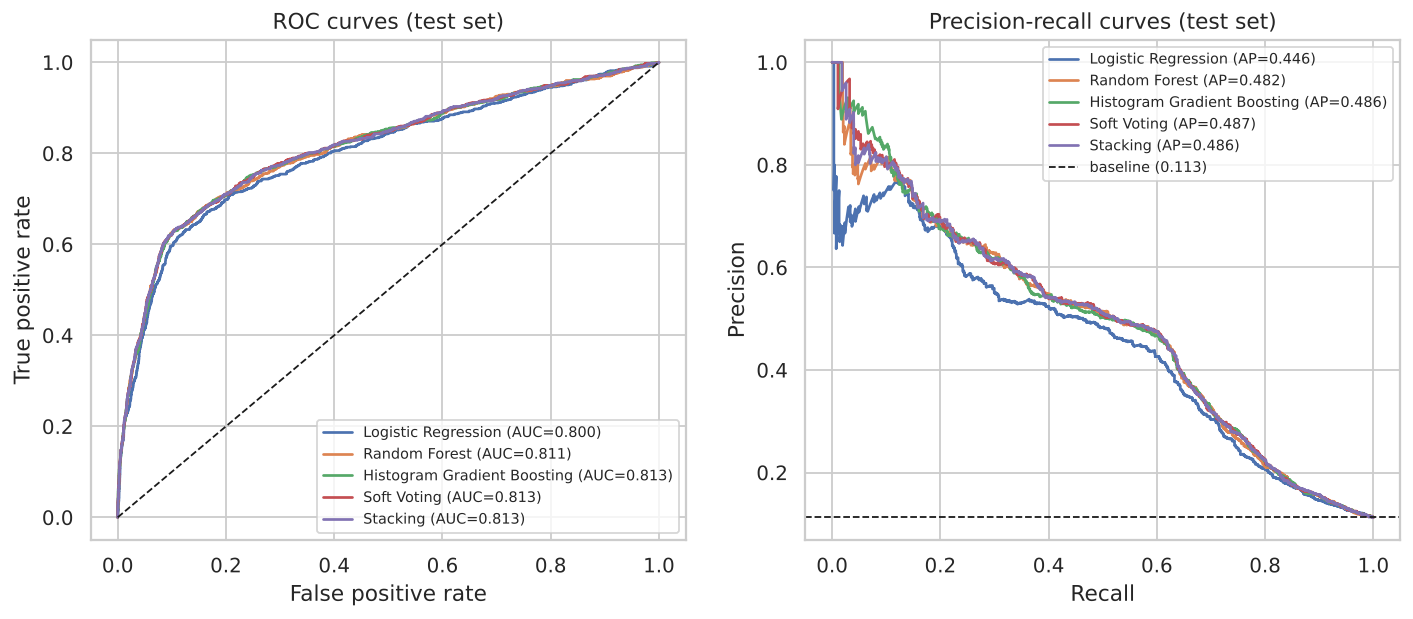

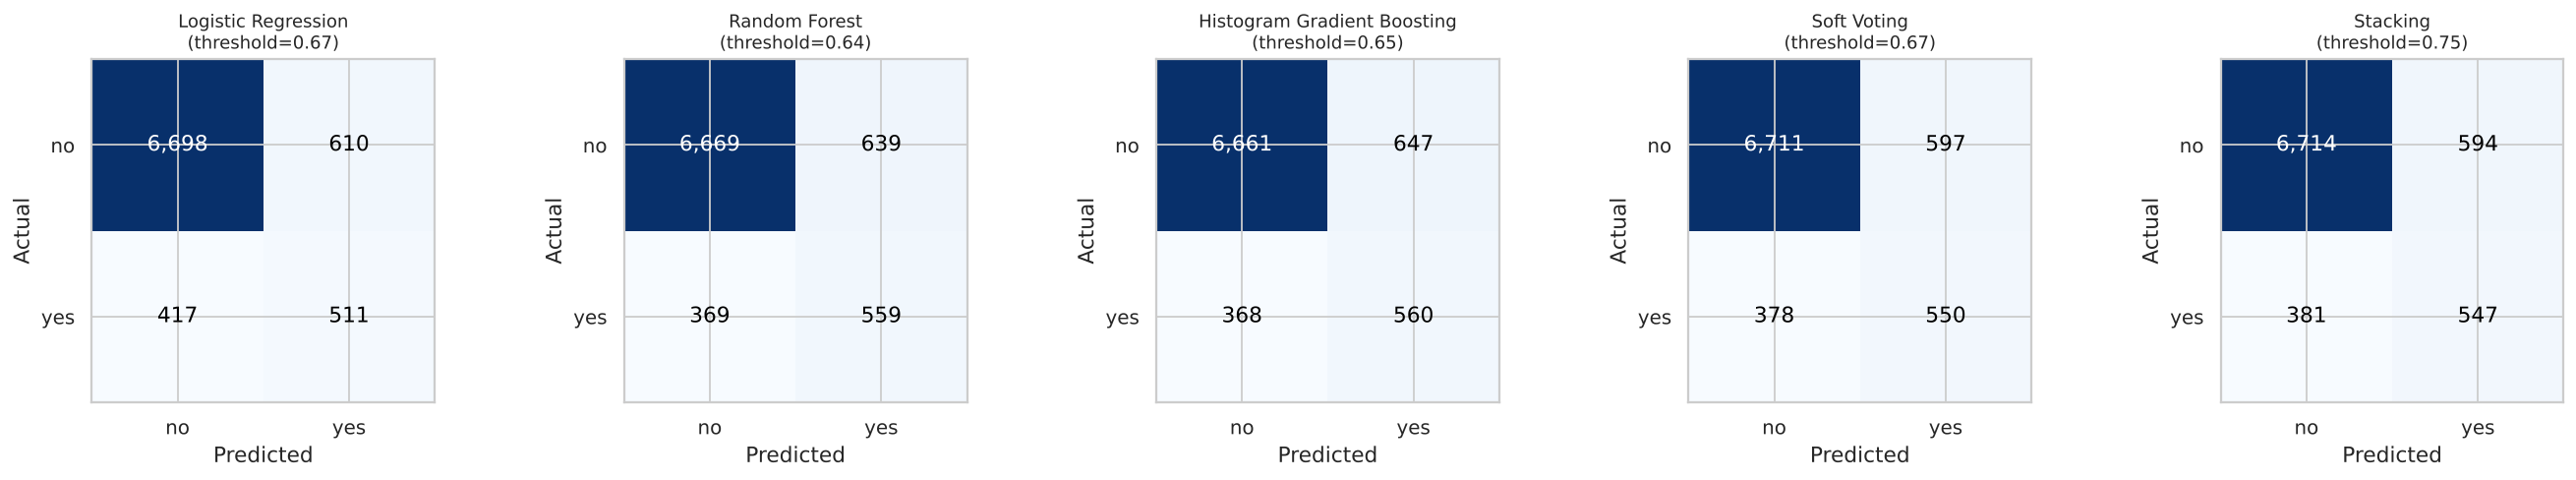

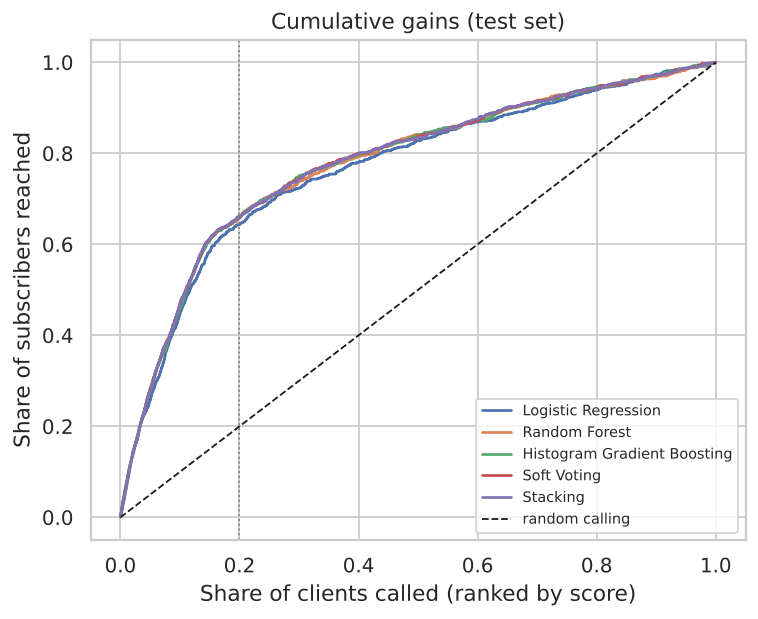

In [30]:
labels = {**MODEL_LABELS, "voting": "Soft Voting", "stacking": "Stacking"}
named = {labels[k]: v for k, v in probas.items()}
ev.plot_curves(y_te, named); ev.plot_confusion_matrices(y_te, named, {labels[k]: v for k, v in thresholds.items()})
ev.plot_gain_chart(y_te, named)
for f in ["10_roc_pr_curves.png", "11_confusion_matrices.png", "12_cumulative_gains.png"]:
    display(Image(FIG_DIR / f))

### H2. What drives the recommended model? (permutation importance on the test set)

In [31]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(fitted[best_single], X_te, y_te, scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X_te.columns).sort_values("mean")
imp.to_csv(RESULTS_DIR / "permutation_importance.csv")
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=sns.color_palette("deep")[2])
ax.set(xlabel="Drop in test PR-AUC when shuffled", title=f"Permutation importance: {labels[best_single]}")
fig.savefig(FIG_DIR / "13_permutation_importance.png", dpi=130, bbox_inches="tight"); plt.show()
imp.sort_values("mean", ascending=False).head(10).round(4)

,mean,std
emp_var_rate,0.0390,0.0071
nr_employed,0.0329,0.0066
euribor3m,0.0313,0.0067
contact,0.0248,0.0037
poutcome,0.0198,0.0056
month,0.0102,0.0025
cons_price_idx,0.0091,0.0017
prev_contacted,0.0087,0.0024
day_of_week,0.0078,0.0019
cons_conf_idx,0.0069,0.0019


### H3. Business view: calls needed per subscriber (cross-validated best single model)

In [32]:
rows = []
for frac in (0.1, 0.2, 0.3, 0.5, 1.0):
    cap, lift = ev.lift_at(y_te.values, probas[best_single], frac)
    n_called = int(np.ceil(frac * len(y_te))); n_subs = int(round(cap * y_te.sum()))
    rows.append({"share called": frac, "clients called": n_called, "subscribers reached": n_subs,
                 "share of subscribers": round(cap, 3), "lift": round(lift, 2),
                 "calls per subscriber": round(n_called / n_subs, 2)})
biz = pd.DataFrame(rows).set_index("share called"); biz.to_csv(RESULTS_DIR / "business_gains.csv"); biz

,clients called,subscribers reached,share of subscribers,lift,calls per subscriber
share called,,,,,
0.1,824,431,0.464,4.64,1.91
0.2,1648,610,0.657,3.29,2.70
0.3,2471,686,0.739,2.46,3.60
0.5,4118,781,0.842,1.68,5.27
1.0,8236,928,1.000,1.00,8.88


In [33]:
import joblib
summary = {"tuning": tune_info, "top2": top2, "excluded": excluded, "thresholds": thresholds,
           "bootstrap_ci": cis, "ensemble_vs_best_single": {f"{a}|{b}": v for (a, b), v in diffs.items()}}
json.dump(summary, open(RESULTS_DIR / "summary.json", "w"), indent=2, default=float)
joblib.dump(fitted, RESULTS_DIR / "fitted_models.joblib", compress=3)
print("Saved results to", RESULTS_DIR)

Saved results to /home/user/bank-marketing-ml/results


## Recommendation
* Both tree models clearly beat Logistic Regression (test PR-AUC about +0.04, outside bootstrap noise).
* Random Forest and Gradient Boosting were indistinguishable in cross-validation and swapped places on the test set.
* Soft voting of the two had the best test PR-AUC, ROC-AUC, F1 and MCC. Its gain over the cross-validated best model (Random Forest) is small (+0.005 PR-AUC) but its paired-bootstrap interval excludes zero; against Gradient Boosting alone the difference is not detectable.
* Stacking matched voting on ranking but took about six times longer to train.

**Recommended model: soft-voting ensemble (Random Forest + Histogram Gradient Boosting)**, used as a ranking score with a business-chosen cut-off. Histogram Gradient Boosting alone is an acceptable simpler fallback. The full argument, limitations (economic drift, calibration, fairness) and business impact are in `report/technical_report.md`.